# 04 · Hybrid membership functions

Phase 4 of the reimplementation of Indian Patent No. 601763. This is the patent's core idea: for every linguistic term, the membership of a value is the **element-wise maximum of a trapezoid and a Gaussian**. The trapezoid gives a bounded plateau ("clearly Low"), the Gaussian a smooth, focused peak; the patent's FIG. 4 shows the construction with hand-picked parameters.

Here every parameter is **derived from the training split, from observed (non-imputed) values only**:

| component | parameter | source |
|---|---|---|
| trapezoid | a, b, c, d | training quantiles 20 / 40 / 60 / 80 %. Low = (−∞, −∞, q20, q40), Normal = (q20, q40, q60, q80), High = (q60, q80, ∞, ∞) |
| Gaussian | μ, σ | mean and standard deviation of the training values whose trapezoid membership in that term is ≥ 0.5; μ clamped into the plateau [b, c] |

**Which attributes get fuzzy terms.** Only the four continuous ones in the BBSO subset (`age`, `trestbps`, `thalch`, `oldpeak`) get Low / Normal / High. The categorical attributes (`cp`, `restecg`, `exang`, `slope`, `thal`) and the vessel count `ca` get **crisp** terms: one per category, membership 1 for the patient's own category and 0 otherwise. A chest-pain type or an ECG finding is a recorded fact with no ordering and no overlap between categories, and `ca` has four integer values that are mostly imputed; spreading them over fuzzy terms would add uncertainty the data does not contain.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
from IPython.display import Image

from hfm import config, data
from hfm.membership import Fuzzifier, shape_check

pd.set_option("display.width", 130)
R = "../results/"
runs = __import__("json").load(open(R + "03_runtime.json"))
attrs = runs["chosen_subset"]
attrs

['age',
 'trestbps',
 'thalch',
 'oldpeak',
 'ca',
 'cp',
 'restecg',
 'exang',
 'slope',
 'thal']

## 1. Fit on the training split

In [2]:
df = data.load_dataset()
train, test = data.make_split(df)
fz = Fuzzifier(attrs).fit(train)
print("continuous (hybrid):", fz.continuous)
print("crisp:              ", fz.crisp)
fz.params().round(2)

continuous (hybrid): ['age', 'trestbps', 'thalch', 'oldpeak']
crisp:               ['ca', 'cp', 'restecg', 'exang', 'slope', 'thal']


,attribute,term,a,b,c,d,mu,sigma,mu_raw,mu_clamped
0,age,Low,-inf,-inf,45.0,52.00,41.95,4.73,41.95,False
1,age,Normal,45.0,52.00,56.0,61.00,54.00,2.73,54.00,False
2,age,High,56.0,61.00,inf,inf,63.85,4.30,63.85,False
3,trestbps,Low,-inf,-inf,120.0,125.40,114.34,6.89,114.34,False
4,trestbps,Normal,120.0,125.40,134.0,145.00,130.29,3.76,130.29,False
5,trestbps,High,134.0,145.00,inf,inf,151.63,13.07,151.63,False
6,thalch,Low,-inf,-inf,115.0,130.00,106.78,12.80,106.78,False
7,thalch,Normal,115.0,130.00,145.8,160.00,138.70,8.56,138.70,False
8,thalch,High,145.8,160.00,inf,inf,167.24,10.05,167.24,False
9,oldpeak,Low,-inf,-inf,0.0,0.41,-0.03,0.23,-0.03,False


The parameters are in clinical units, so the terms can be read directly: for resting blood pressure, *Low* is fully true up to 120 mm Hg and fades out by 125, *Normal* is fully true from 125 to 134, *High* is fully true from 145 upward. The Gaussian of each term sits on its plateau (μ) with a spread (σ) learned from the patients in that region.

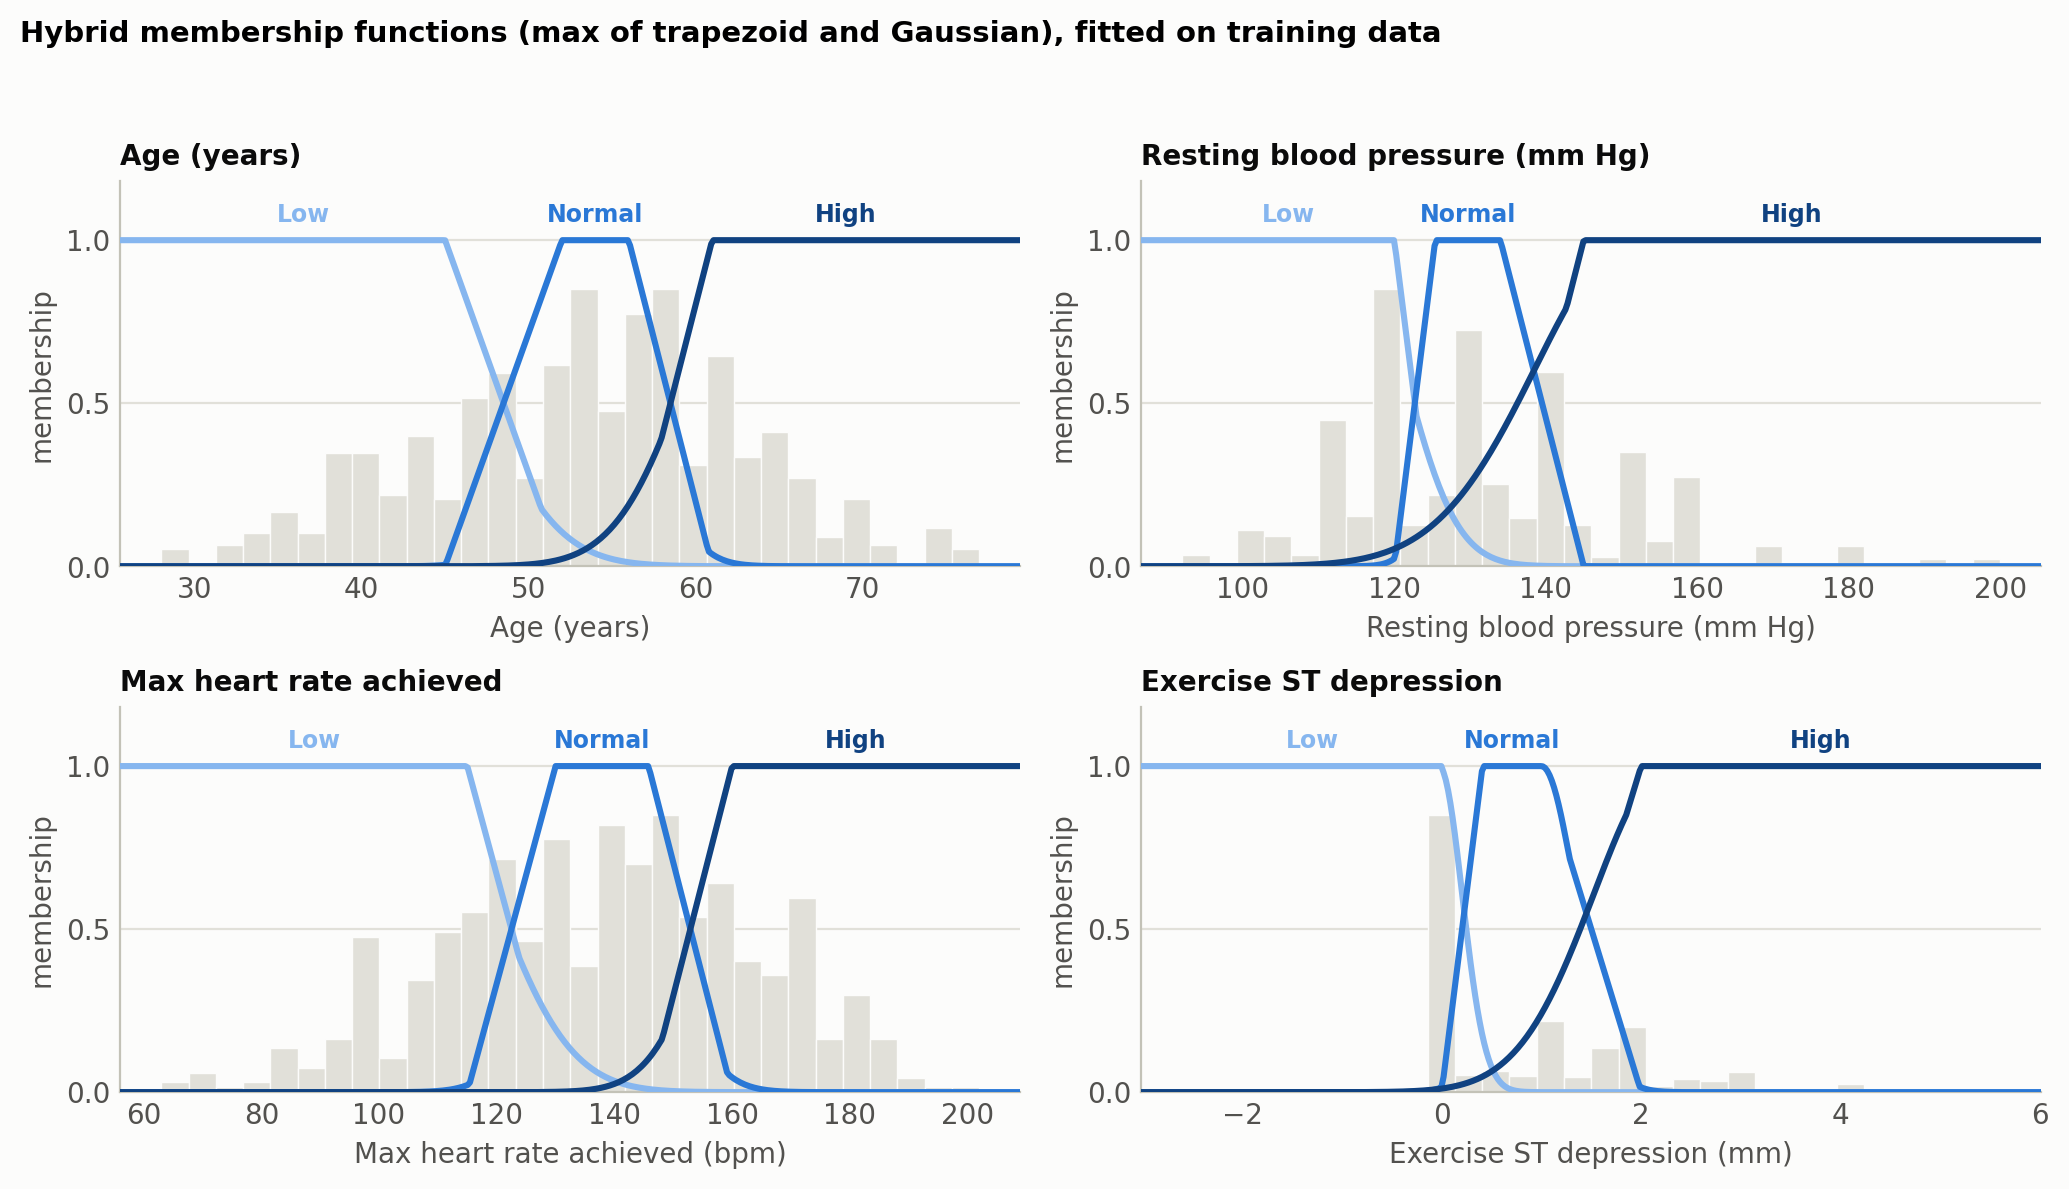

In [3]:
Image("../figures/04_membership_overview.png", width=900)

The faint histogram is the training distribution. Each detailed figure below also shows the two components (dotted trapezoid, dashed Gaussian) under the solid hybrid curve.

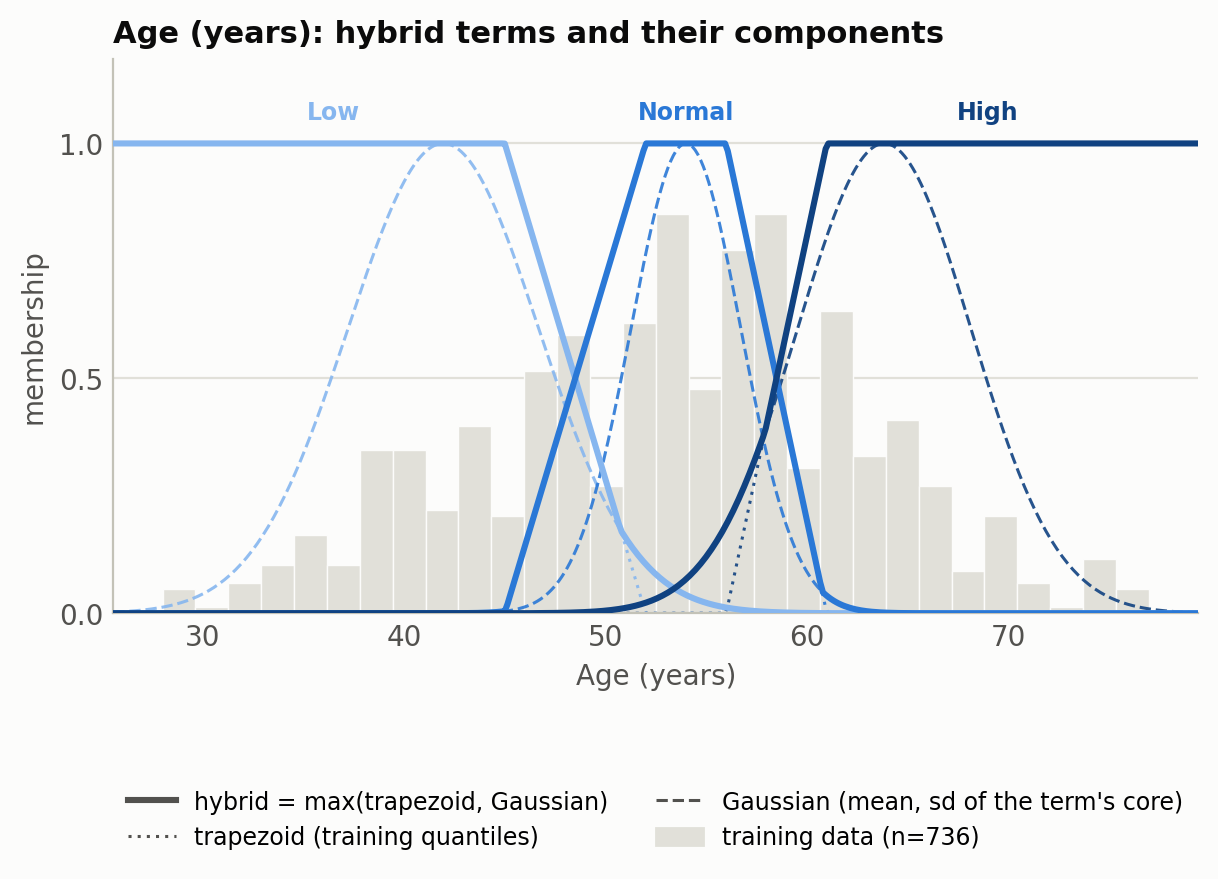

In [4]:
Image("../figures/04_mf_age.png", width=720)

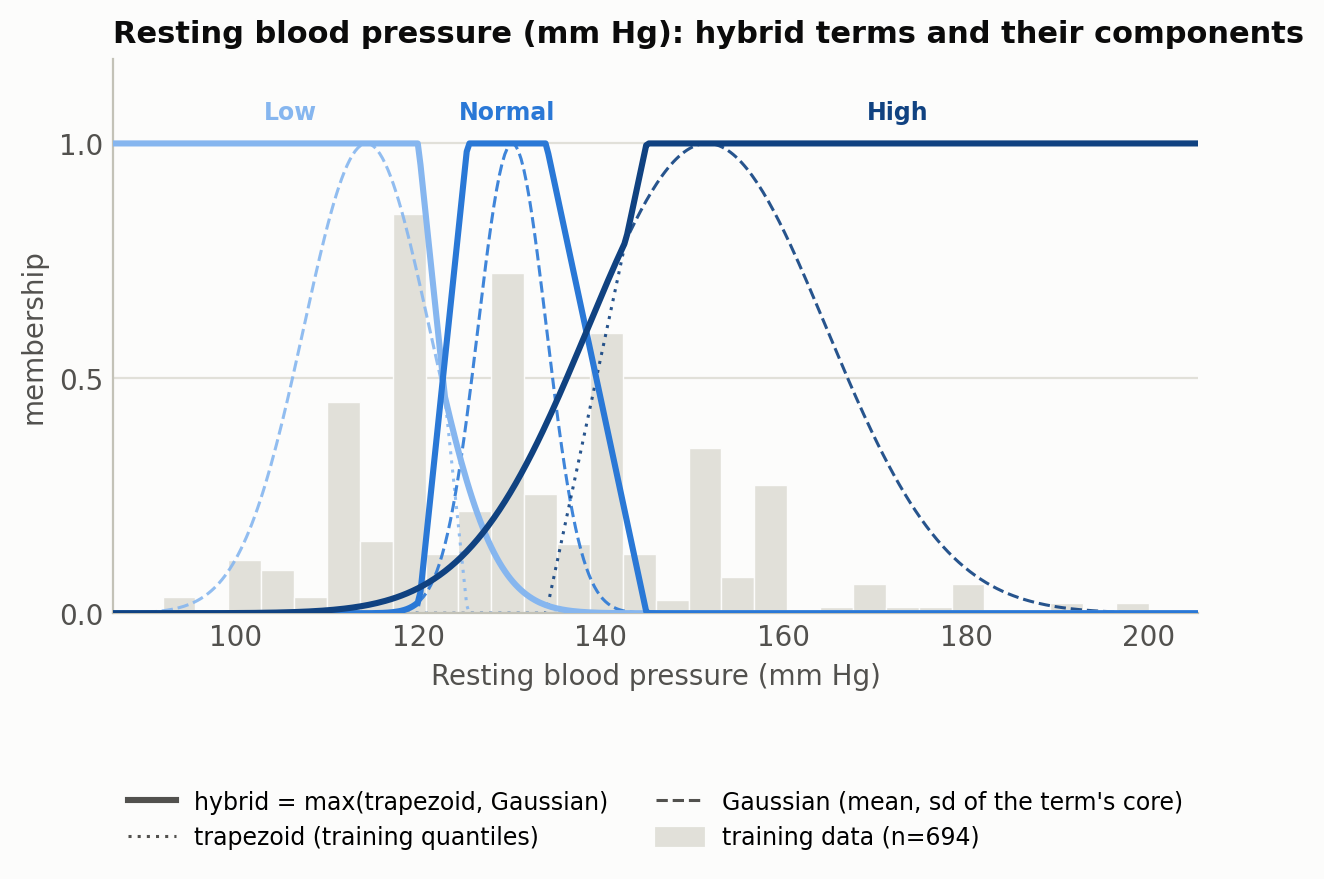

In [5]:
Image("../figures/04_mf_trestbps.png", width=720)

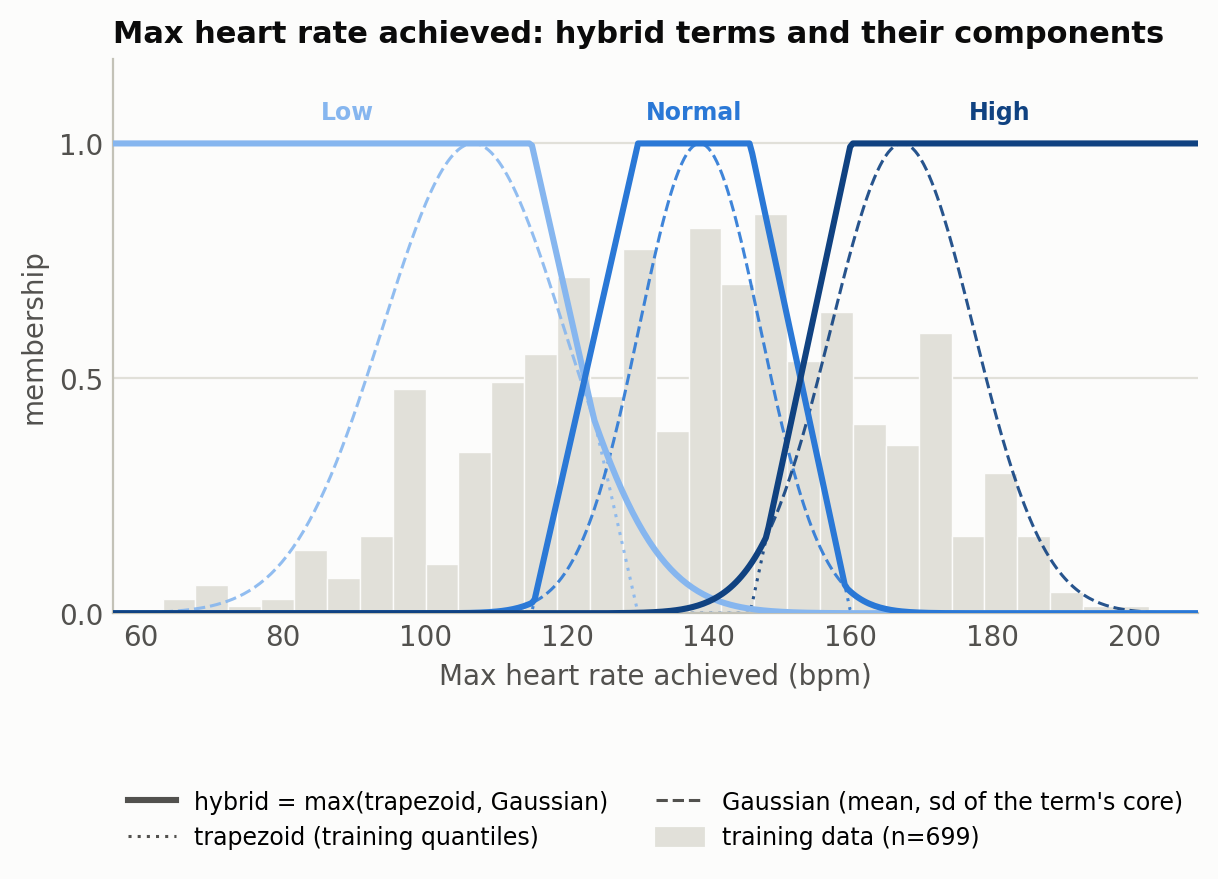

In [6]:
Image("../figures/04_mf_thalch.png", width=720)

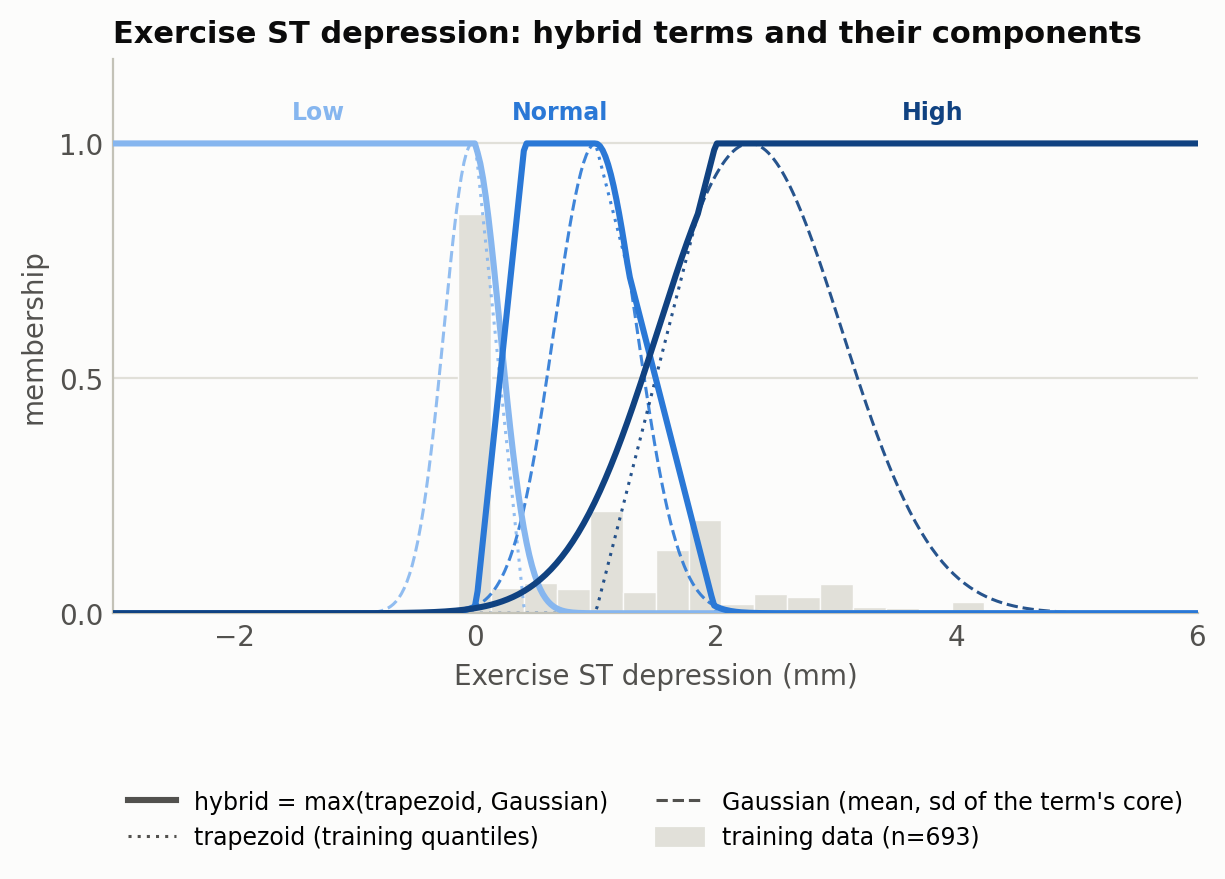

In [7]:
Image("../figures/04_mf_oldpeak.png", width=720)

## 2. Shape check: does the max stay readable?

Taking a maximum of two shapes can produce a two-humped term if the Gaussian peak sits outside the trapezoid plateau (that is what happens in the patent's own FIG. 4, where the Gaussian lies between two plateaus). `shape_check` samples each hybrid term on a fine grid and counts its peaks.

In [8]:
checks = pd.concat([shape_check(fz.families[a]) for a in fz.continuous], ignore_index=True)
checks.round(3)

,attribute,term,peaks,quasi_concave,gauss_extension,mu_inside_plateau
0,age,Low,1,True,0.105,True
1,age,Normal,1,True,0.037,True
2,age,High,1,True,0.188,True
3,trestbps,Low,1,True,0.276,True
4,trestbps,Normal,1,True,0.024,True
5,trestbps,High,1,True,0.401,True
6,thalch,Low,1,True,0.193,True
7,thalch,Normal,1,True,0.045,True
8,thalch,High,1,True,0.102,True
9,oldpeak,Low,1,True,0.171,True


All twelve terms are single-peaked. One needed the clamp: the `oldpeak` *Normal* core mean was 1.05 mm, just past the plateau's right edge at 1.00 mm (the distribution is right-skewed), which on the unclamped fit produced a second bump of height 0.01 and was flagged with two peaks. With μ clamped to 1.00 the term is single-peaked; `mu_raw` and `mu_clamped` in the parameter table record this. The clamp is also a guarantee, not just a fix: left of the plateau both components are non-decreasing, right of it both are non-increasing, so their maximum is single-peaked by construction.

`gauss_extension` is how much the Gaussian lifts membership above the trapezoid at its most. It is largest for `trestbps` *High* (0.40): the Gaussian is wide (σ = 13 mm Hg) and reaches back below 145 mm Hg, softening the trapezoid's hard ramp. That is the hybrid doing its intended job.

## 3. Fuzzified data

`Fuzzifier.transform` takes the cleaned raw frame (NaNs allowed, clinical units) and returns one column per (attribute, term). **A missing reading gets membership 0 in every term of its attribute**: no rule can fire on it, and the inference step (phase 5) skips that attribute and renormalises the weights of the measured ones. Nothing is filled, so there is no missingness indicator and no hospital proxy entering the fuzzy model. The fuzzifier records which cells were missing so an explanation can say "not measured".

In [9]:
M = fz.transform(train)
print(M.shape)
M.round(2).head()

(736, 31)


,age=Low,age=Normal,age=High,trestbps=Low,trestbps=Normal,trestbps=High,thalch=Low,thalch=Normal,thalch=High,oldpeak=Low,...,restecg=normal,restecg=st-t abnormality,exang=False,exang=True,slope=downsloping,slope=flat,slope=upsloping,thal=fixed defect,thal=normal,thal=reversable defect
0,1.00,0.00,0.00,0.08,1.00,0.25,0.00,0.00,1.0,1.00,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.00,0.40,0.60,0.02,1.00,0.40,0.00,0.02,1.0,0.00,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.71,0.29,0.00,1.00,0.00,0.01,0.80,0.20,0.0,0.00,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.01,0.80,0.28,0.00,0.00,1.00,0.73,0.27,0.0,0.00,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.02,1.00,0.12,1.00,0.02,0.05,1.00,0.00,0.0,0.37,...,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [10]:
pd.read_csv(R + "04_crisp_terms.csv")

,attribute,categories,n_terms,training_mode,missing_train,missing_train_pct
0,ca,0 | 1 | 2 | 3,4,0,492,66.8
1,cp,asymptomatic | atypical angina | non-anginal |...,4,asymptomatic,0,0.0
2,restecg,lv hypertrophy | normal | st-t abnormality,3,normal,1,0.1
3,exang,False | True,2,False,37,5.0
4,slope,downsloping | flat | upsloping,3,flat,248,33.7
5,thal,fixed defect | normal | reversable defect,3,normal,387,52.6


Two thirds of the training rows have no `ca` reading and half have no `thal`; for those patients every `ca=…` / `thal=…` column is 0 and the attribute simply does not take part. This is the fuzzy model's answer to the hospital-linked imputation noted in phase 3: the baselines see a filled value, the fuzzy model sees nothing.

In [11]:
cov = pd.read_csv(R + "04_term_coverage.csv", index_col=0)
cov.round(3).T

,age=Low,age=Normal,age=High,trestbps=Low,trestbps=Normal,trestbps=High,thalch=Low,thalch=Normal,thalch=High,oldpeak=Low,...,restecg=normal,restecg=st-t abnormality,exang=False,exang=True,slope=downsloping,slope=flat,slope=upsloping,thal=fixed defect,thal=normal,thal=reversable defect
mean_membership_train,0.311,0.390,0.335,0.373,0.316,0.373,0.298,0.388,0.294,0.456,...,0.599,0.189,0.584,0.365,0.067,0.378,0.219,0.053,0.212,0.209
mean_membership_test,0.275,0.396,0.366,0.289,0.301,0.417,0.295,0.330,0.303,0.371,...,0.598,0.217,0.533,0.370,0.076,0.364,0.228,0.038,0.217,0.207


## Outputs

`results/04_membership_params.csv`, `04_shape_check.csv`, `04_crisp_terms.csv`, `04_term_coverage.csv`; `figures/04_membership_overview.png` and one `04_mf_<attribute>.png` per continuous attribute.

**Next phase:** data-driven rule generation (Wang–Mendel) over these terms, weighted-average aggregation, centroid defuzzification.